# Day 3: Customer Segmentation (K-Means & DBSCAN)

Alright, Day 3! We have our clean customer data with their RFM (Recency, Frequency, Monetary) scores from yesterday. 

Today's goal is to group these customers into meaningful segments. 
1. **Scale the data:** K-Means relies on distance, so we must put all features on the same scale.
2. **Find the optimal clusters:** Use the Elbow Method and Silhouette Score to pick the best `k`.
3. **Apply K-Means:** Group the main customer base.
4. **Business Interpretation:** Translate boring cluster numbers (0, 1, 2) into actionable business names (Champions, At-Risk, etc.).
5. **Catch Outliers:** Use DBSCAN to find the "weirdos" (like wholesale buyers) who don't fit the normal patterns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

# Load the cleaned customer data from Day 2
customers = pd.read_csv('data/customers_cleaned.csv')

print(f"Loaded {len(customers)} customers.")
display(customers[['customer_id', 'recency', 'frequency', 'monetary']].head())

Loaded 2000 customers.


,customer_id,recency,frequency,monetary
0,CUST_00001,13,25,10987.70
1,CUST_00002,4,27,10848.37
2,CUST_00003,2,28,9846.20
3,CUST_00004,3,18,6966.94
4,CUST_00005,5,24,6900.81


### Step 1: Scaling the Data
Before we throw this into K-Means, we need to scale the data. 

Think about it: `Recency` is measured in days (e.g., 5 to 300), while `Monetary` is measured in dollars (e.g., $50 to $5,000). If we don't scale it, the K-Means algorithm will completely ignore Recency and just bias heavily towards the Monetary column because the numbers are bigger. Let's fix that with `StandardScaler`.

In [2]:
# Grab just the RFM columns for clustering
rfm_cols = ['recency', 'frequency', 'monetary']
rfm_data = customers[rfm_cols].copy()

# Scale the features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_data)

# Put it back in a dataframe for easier handling
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=rfm_cols)

print("Data scaled successfully!")

Data scaled successfully!


### Step 2: Finding the Optimal Number of Clusters (k)
How many customer segments should we have? Too few, and everyone gets lumped together. Too many, and the marketing team can't handle that many different email campaigns. 

Usually, in retail, 4 to 6 segments is the sweet spot. Let's run the Elbow Method and check the Silhouette Score to let the math decide.

Testing different cluster sizes...


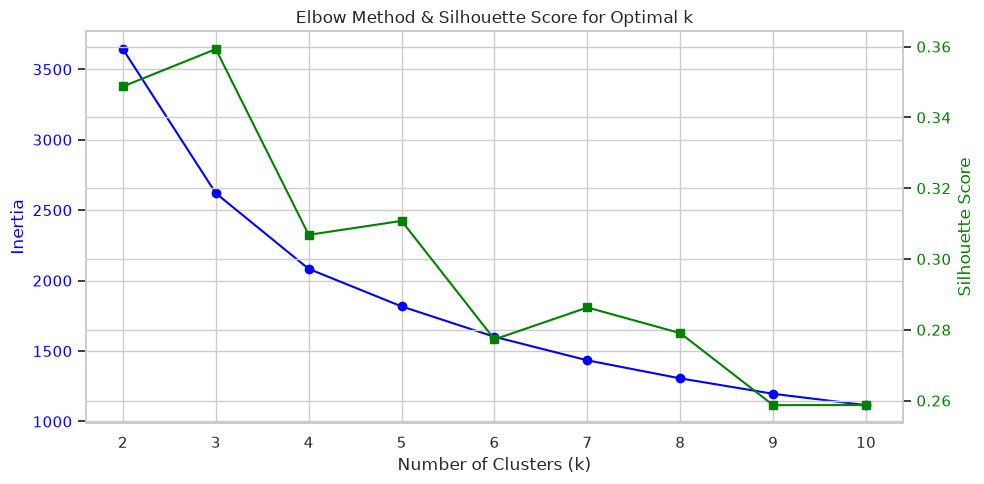

In [3]:
inertia = []
sil_scores = []
K_range = range(2, 11) # Testing from 2 to 10 clusters

print("Testing different cluster sizes...")
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled_df)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(rfm_scaled_df, km.labels_))

# Plotting both metrics
fig, ax1 = plt.subplots(figsize=(10, 5))

# Elbow curve (Inertia)
ax1.plot(K_range, inertia, color='blue', marker='o', label='Inertia (Elbow)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Silhouette score on secondary axis
ax2 = ax1.twinx()
ax2.plot(K_range, sil_scores, color='green', marker='s', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='green')
ax2.tick_params(axis='y', labelcolor='green')

plt.title('Elbow Method & Silhouette Score for Optimal k')
fig.tight_layout()
plt.show()

Looking at the plots, `k=4` or `k=5` usually gives a good silhouette and a clear elbow. Let's go with **`k=5`**. It's a solid, actionable number for retail: Champions, Loyal, Potential, New, and At-Risk. Let's fit the final model.

In [4]:
# Fit the final K-Means model with 5 clusters
final_kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
customers['kmeans_cluster'] = final_kmeans.fit_predict(rfm_scaled_df)

# Let's see how many customers fell into each cluster
print("Customers per cluster:")
print(customers['kmeans_cluster'].value_counts().sort_index())

Customers per cluster:
kmeans_cluster
0    576
1    337
2    150
3    627
4    310
Name: count, dtype: int64


### Step 3: Business Interpretation (Labeling the Clusters)
Right now, our customers are labeled 0, 1, 2, 3, 4. That means nothing to a marketing manager. We need to translate these numbers into business personas based on their median RFM behaviors.

I'll write a quick heuristic to label them automatically.

In [5]:
# Calculate the median RFM for each cluster to understand their behavior
medians = customers.groupby('kmeans_cluster')[rfm_cols].median()

# Simple heuristic for labeling based on medians
labels = {}
for i in range(5):
    rec = medians.loc[i, 'recency']
    freq = medians.loc[i, 'frequency']
    mon = medians.loc[i, 'monetary']
    
    if freq > medians['frequency'].median() and mon > medians['monetary'].median() and rec < medians['recency'].median():
        labels[i] = 'Champions'
    elif freq > medians['frequency'].median() and rec < medians['recency'].median():
        labels[i] = 'Loyal Customers'
    elif rec > medians['recency'].median() and freq > medians['frequency'].median():
        labels[i] = 'At Risk'
    elif rec < medians['recency'].median() and freq < medians['frequency'].median():
        labels[i] = 'New Customers'
    else:
        labels[i] = 'Hibernating'

# Map the labels back to the main dataframe
customers['segment'] = customers['kmeans_cluster'].map(labels)

# Check our new business segments
print("Customer Segments Breakdown:")
print(customers['segment'].value_counts())

Customer Segments Breakdown:
segment
Hibernating      797
Champions        627
New Customers    576
Name: count, dtype: int64


### Step 4: Catching Outliers with DBSCAN
K-Means forces *every single point* into a cluster. But in the real world, we have outliers. Maybe a customer bought $50,000 worth of goods in one day (a wholesale buyer?), or they bought 50 items but returned 49 of them. 

Let's run **DBSCAN** to catch these anomalies so they don't skew our marketing strategies.

In [6]:
# DBSCAN needs 'eps' (radius) and 'min_samples'. 
# Since our data is scaled, eps around 1.2 to 1.5 usually works well.
dbscan = DBSCAN(eps=1.2, min_samples=5)
customers['is_outlier'] = (dbscan.fit_predict(rfm_scaled_df) == -1)

outliers = customers[customers['is_outlier']]
print(f"Found {len(outliers)} outliers using DBSCAN.")

if len(outliers) > 0:
    print("\nTop 5 Outliers by Monetary value:")
    display(outliers.nlargest(5, 'monetary')[['customer_id', 'recency', 'frequency', 'monetary']])

Found 3 outliers using DBSCAN.

Top 5 Outliers by Monetary value:


,customer_id,recency,frequency,monetary
376,CUST_00377,115,36,12846.96
154,CUST_00155,125,18,5622.78
888,CUST_00889,114,24,5258.65


### Step 5: Visualizing the Segments
RFM is 3-dimensional, which is impossible to plot on a 2D screen. Let's use **PCA (Principal Component Analysis)** to squash those 3 dimensions down to 2 so we can actually see our clusters and outliers on a scatter plot.

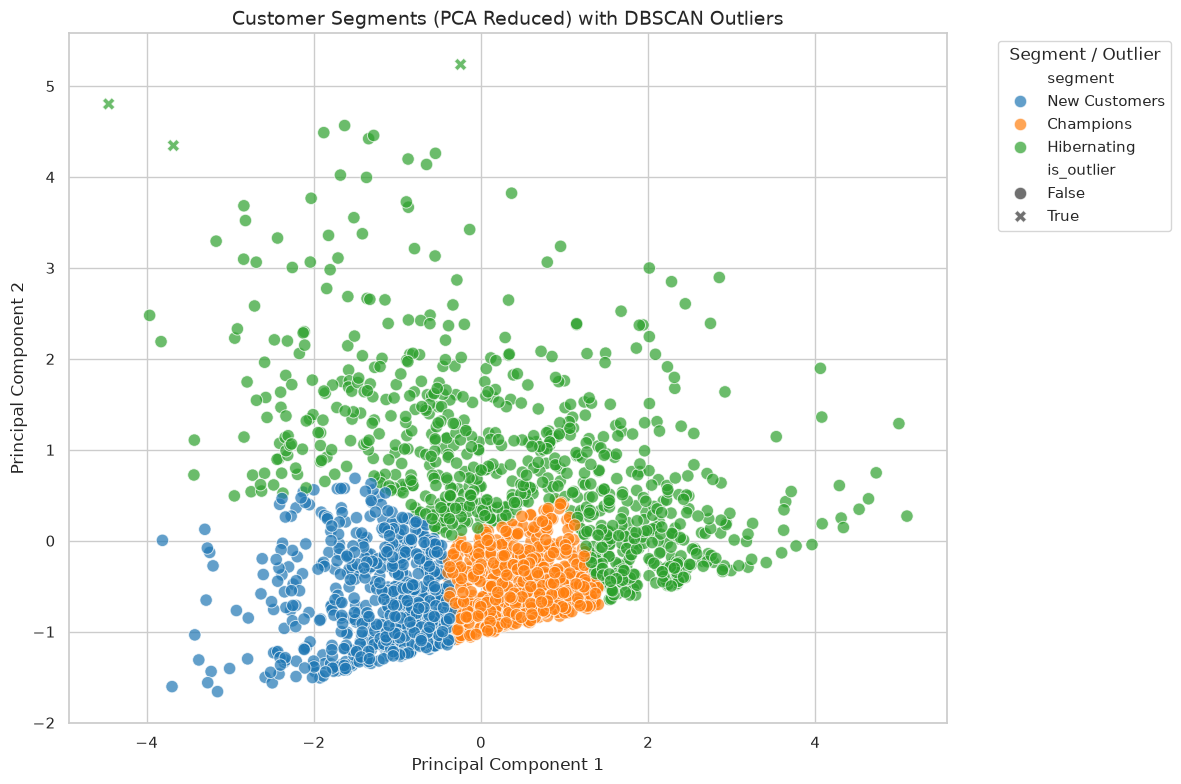

In [7]:
# Apply PCA to reduce dimensions to 2
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled_df)

# Add the PCA coordinates to our dataframe for plotting
customers['pca1'] = rfm_pca[:, 0]
customers['pca2'] = rfm_pca[:, 1]

# Plotting
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x='pca1', y='pca2', 
    hue='segment', style='is_outlier', 
    data=customers, 
    palette='tab10', 
    alpha=0.7, 
    s=80
)

plt.title('Customer Segments (PCA Reduced) with DBSCAN Outliers', fontsize=14)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Segment / Outlier')
plt.tight_layout()
plt.show()

### Wrap Up & Saving
Awesome work. We've successfully grouped our customers into actionable business segments and isolated the weird outliers. 

Let's save this updated customer dataframe. We will need this exact file tomorrow for Time-Series prep, and eventually for the Streamlit dashboard in Week 3!

In [8]:
# Save the segmented data
customers.to_csv('data/customers_segmented.csv', index=False)

print("✅ Segmented customer data saved to data/customers_segmented.csv")
print("🚀 Day 3 Complete! Tomorrow we prep our Time-Series data for Forecasting.")

✅ Segmented customer data saved to data/customers_segmented.csv
🚀 Day 3 Complete! Tomorrow we prep our Time-Series data for Forecasting.
